# Ferdi Fadillah (ff2364)
# Deep Learning (Fall 2026)
# Project 1

## 1. Import Library & Setup

In [1]:
import os, glob, time, copy, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch 2.8.0+cu128 | device: cuda | NVIDIA A100-SXM4-40GB


## 2. Config

In [2]:
DATA_DIR    = "./data"
OUT_DIR     = "./outputs"
VAL_SIZE    = 5000 #45k/5k train/val split
EPOCHS      = 400      
BATCH_SIZE  = 128
LR_MAX      = 0.1
WEIGHT_DECAY= 5e-4
LABEL_SMOOTH= 0.1
EMA_DECAY   = 0.999
MIX_PROB    = 0.5
NUM_WORKERS = 0 if os.name == "nt" else min(8, len(os.sched_getaffinity(0)))  
USE_AMP     = device.type == "cuda"

os.makedirs(OUT_DIR, exist_ok=True)
CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

## 3. Data

In [3]:
import io, zipfile
from PIL import Image

# load dataset images
def load_images(filenames, name):
    folder = os.path.join(DATA_DIR, name)
    if os.path.isdir(folder) and all(os.path.exists(os.path.join(folder, f)) for f in filenames):
        print(f"{name}: reading {len(filenames)} images from folder")
        return np.stack([np.array(Image.open(os.path.join(folder, f)).convert("RGB")) for f in filenames])
    zpath = folder + ".zip"
    print(f"{name}: reading {len(filenames)} images from {zpath}")
    with zipfile.ZipFile(zpath) as z:
        index = {os.path.basename(n): n for n in z.namelist() if n.endswith(".png")}
        return np.stack([np.array(Image.open(io.BytesIO(z.read(index[f]))).convert("RGB")) for f in filenames])

cache = os.path.join(OUT_DIR, "data_cache.npz")
train_df = pd.read_csv(os.path.join(DATA_DIR, "train_labels.csv"))
test_df  = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
if os.path.exists(cache):
    d = np.load(cache); x_all, x_test = d["x_all"], d["x_test"]
else:
    x_all  = load_images(train_df["filename"].tolist(), "train_images")
    x_test = load_images(test_df["filename"].tolist(), "test_images")
    np.savez(cache, x_all=x_all, x_test=x_test)
y_all, test_ids = train_df["label"].values, test_df["id"].values
assert x_all.shape == (len(train_df), 32, 32, 3) and x_test.shape == (len(test_df), 32, 32, 3)

In [4]:
# validation split
rng = np.random.RandomState(SEED)
val_idx = np.concatenate([rng.permutation(np.where(y_all == c)[0])[:VAL_SIZE // 10] for c in range(10)])
train_mask = np.ones(len(y_all), bool); train_mask[val_idx] = False
x_train, y_train = x_all[train_mask], y_all[train_mask]
x_val, y_val = x_all[val_idx], y_all[val_idx]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
print("train class counts:", np.bincount(y_train))

# for normalization
MEAN = x_train.reshape(-1, 3).mean(0) / 255.0
STD  = x_train.reshape(-1, 3).std(0) / 255.0
print("mean", MEAN.round(4), "std", STD.round(4))

train (45000, 32, 32, 3) | val (5000, 32, 32, 3) | test (2000, 32, 32, 3)
train class counts: [4500 4500 4500 4500 4500 4500 4500 4500 4500 4500]
mean [0.4913 0.4821 0.4465] std [0.247  0.2434 0.2615]


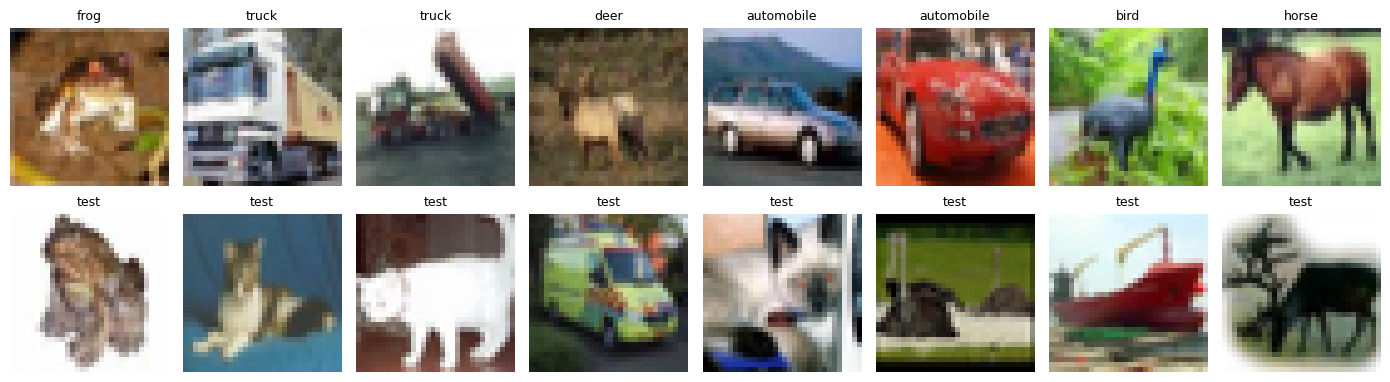

In [5]:
# visualization
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes[0], range(8)):
    ax.imshow(x_train[i]); ax.set_title(CLASSES[y_train[i]], fontsize=9); ax.axis("off")
for ax, img in zip(axes[1], x_test[:8]):
    ax.imshow(img); ax.set_title("test", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [6]:
class NumpyDS(Dataset):
    def __init__(self, x, y=None, tf=None):
        self.x, self.y, self.tf = x, y, tf
    def __len__(self): return len(self.x)
    def __getitem__(self, i):
        img = T.functional.to_pil_image(self.x[i])
        img = self.tf(img)
        return (img, int(self.y[i])) if self.y is not None else img

# normalization and data augmentation
normalize = T.Normalize(MEAN.tolist(), STD.tolist())
train_tf = T.Compose([
    T.RandomCrop(32, padding=4, padding_mode="reflect"),
    T.RandomHorizontalFlip(),
    T.AutoAugment(T.AutoAugmentPolicy.CIFAR10),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    normalize,
    T.RandomErasing(p=0.5, scale=(0.02, 0.15), value=0),  # Cutout-style
])
test_tf = T.Compose([T.ToTensor(), normalize])

# data loader
loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=device.type == "cuda", persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(NumpyDS(x_train, y_train, train_tf), batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_kw)
val_loader   = DataLoader(NumpyDS(x_val, y_val, test_tf), batch_size=512, shuffle=False, **loader_kw)
test_loader  = DataLoader(NumpyDS(x_test, None, test_tf), batch_size=512, shuffle=False, **loader_kw)

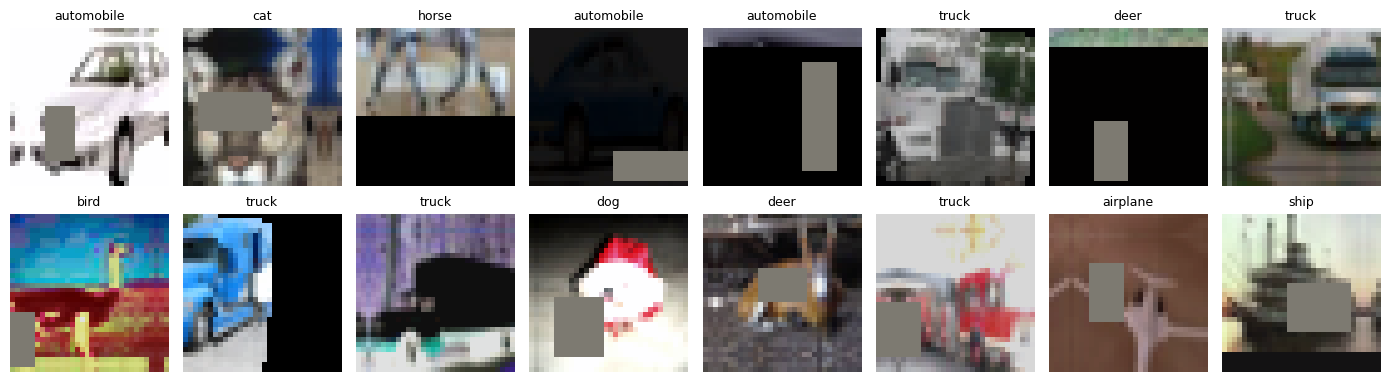

In [7]:
# see example of augmented training samples
imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, imgs, labels):
    img = img.permute(1, 2, 0).numpy() * STD + MEAN
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(CLASSES[lb], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Model

| Param | Value |
|---|---|
| N (residual layers) | 3 |
| B_i (residual blocks) | 3, 4, 3 |
| C_i (channels) | 64, 128, 256 |
| F_i (conv. kernel size) | 3 |
| K_i (skip connection kernel size) | 1 |
| P (avg pool kernel size) | 8 (global) |

In [8]:
class BasicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1, k=3, skip_k=1):
        super().__init__()
        p = k // 2
        self.conv1 = nn.Conv2d(in_c, out_c, k, stride, p, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, k, 1, p, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, skip_k, stride, skip_k // 2, bias=False),
                nn.BatchNorm2d(out_c))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ResNet(nn.Module):
    def __init__(self, channels=(64, 128, 256), blocks=(3, 4, 3), k=3, skip_k=1, num_classes=10, dropout=0.0):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
            nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        layers, in_c = [], channels[0]
        for i, (c, b) in enumerate(zip(channels, blocks)):
            for j in range(b):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(BasicBlock(in_c, c, stride, k, skip_k))
                in_c = c
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(in_c, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for m in self.modules():   # zero-init last BN in each block (Goyal et al., 2017)
            if isinstance(m, BasicBlock):
                nn.init.zeros_(m.bn2.weight)

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.drop(torch.flatten(self.pool(x), 1)))


model = ResNet().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")
assert n_params <= 5_000_000, "Model exceeds 5M parameter budget!"

Trainable parameters: 4,623,178


In [9]:
try:
    from torchsummary import summary
    summary(model, (3, 32, 32), device=device.type)
except ImportError:
    print("torchsummary not installed (pip install torchsummary); parameter count above is authoritative.")

torchsummary not installed (pip install torchsummary); parameter count above is authoritative.


## 5. Training

In [10]:
def tta_logits(net, x):
    out = net(x) + net(torch.flip(x, dims=[3]))
    xp = F.pad(x, (2, 2, 2, 2), mode="reflect")
    for dy, dx in [(0, 2), (4, 2), (2, 0), (2, 4)]:
        out = out + net(xp[:, :, dy:dy+32, dx:dx+32])
    return out

In [11]:
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

decay, no_decay = [], []
for n, p in model.named_parameters():
    (no_decay if p.ndim <= 1 else decay).append(p)
optimizer = torch.optim.SGD([{"params": decay, "weight_decay": WEIGHT_DECAY},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=LR_MAX, momentum=0.9, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR_MAX, epochs=EPOCHS,
                                                steps_per_epoch=len(train_loader), pct_start=0.15,
                                                div_factor=10, final_div_factor=1000)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
ema = torch.optim.swa_utils.AveragedModel(
    model, multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)


@torch.no_grad()
def evaluate(net, loader, tta=False):
    net.eval()
    correct = total = 0; loss_sum = 0.0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=USE_AMP):
            logits = tta_logits(net, x) if tta else net(x)
        loss_sum += F.cross_entropy(logits.float(), y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item(); total += y.size(0)
    return loss_sum / total, 100.0 * correct / total

def mix_batch(x, y):
    if np.random.rand() >= MIX_PROB: return x, y, y, 1.0
    perm = torch.randperm(x.size(0), device=x.device); lam = np.random.beta(1.0, 1.0)
    if np.random.rand() < 0.5:  # CutMix
        H, W = x.shape[2:]; h, w = int(H*math.sqrt(1-lam)), int(W*math.sqrt(1-lam))
        cy, cx = np.random.randint(H), np.random.randint(W)
        y1, y2 = np.clip(cy-h//2, 0, H), np.clip(cy+h//2, 0, H)
        x1, x2 = np.clip(cx-w//2, 0, W), np.clip(cx+w//2, 0, W)
        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
        lam = 1 - (y2-y1)*(x2-x1)/(H*W)
    else:  # Mixup
        x = lam*x + (1-lam)*x[perm]
    return x, y, y[perm], lam

def train_one_epoch():
    model.train()
    correct = total = 0; loss_sum = 0.0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device.type, enabled=USE_AMP):
            xm, ya, yb, lam = mix_batch(x, y)
            logits = model(xm); loss = lam*criterion(logits, ya) + (1-lam)*criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        ema.update_parameters(model)
        loss_sum += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item(); total += y.size(0)
    return loss_sum / total, 100.0 * correct / total



/tmp/ipykernel_7775/2369688441.py:12: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


In [12]:
hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "ema_val_acc": [], "lr": []}
best_acc, best_src = 0.0, None
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    tl, ta = train_one_epoch()
    vl, va = evaluate(model, val_loader)
    _, ea = evaluate(ema.module, val_loader)
    for k, v in zip(hist, [tl, ta, vl, va, ea, optimizer.param_groups[0]["lr"]]): hist[k].append(v)
    if max(va, ea) > best_acc:
        best_acc = max(va, ea)
        best_src = "ema" if ea >= va else "model"
        torch.save((ema.module if best_src == "ema" else model).state_dict(), os.path.join(OUT_DIR, "best.pt"))
    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(f"ep {epoch:3d} | train {tl:.3f}/{ta:5.2f}% | val {vl:.3f}/{va:5.2f}% | ema {ea:5.2f}% "
              f"| best {best_acc:5.2f}% ({best_src}) | {(time.time()-t0)/60:.1f} min")   
pd.DataFrame(hist).to_csv(os.path.join(OUT_DIR, "history.csv"), index=False)

ep   1 | train 2.156/21.23% | val 1.795/33.78% | ema 13.36% | best 33.78% (model) | 0.4 min
ep   5 | train 1.848/38.26% | val 1.250/56.32% | ema 37.48% | best 56.32% (model) | 1.3 min
ep  10 | train 1.632/48.41% | val 0.923/68.52% | ema 62.68% | best 68.52% (model) | 2.4 min
ep  15 | train 1.510/54.01% | val 0.744/78.18% | ema 76.80% | best 78.18% (model) | 3.4 min
ep  20 | train 1.408/59.78% | val 0.639/80.52% | ema 84.16% | best 84.16% (ema) | 4.5 min
ep  25 | train 1.340/62.59% | val 0.622/82.42% | ema 87.76% | best 87.76% (ema) | 5.6 min
ep  30 | train 1.343/61.67% | val 0.637/84.02% | ema 89.54% | best 89.54% (ema) | 6.6 min
ep  35 | train 1.268/65.73% | val 0.579/82.84% | ema 90.70% | best 90.70% (ema) | 7.7 min
ep  40 | train 1.247/66.22% | val 0.569/85.14% | ema 91.38% | best 91.38% (ema) | 8.8 min
ep  45 | train 1.270/64.41% | val 0.472/87.76% | ema 91.84% | best 91.84% (ema) | 9.8 min
ep  50 | train 1.245/65.15% | val 0.483/86.56% | ema 92.08% | best 92.08% (ema) | 10.9 min
e

## 6. Training curves

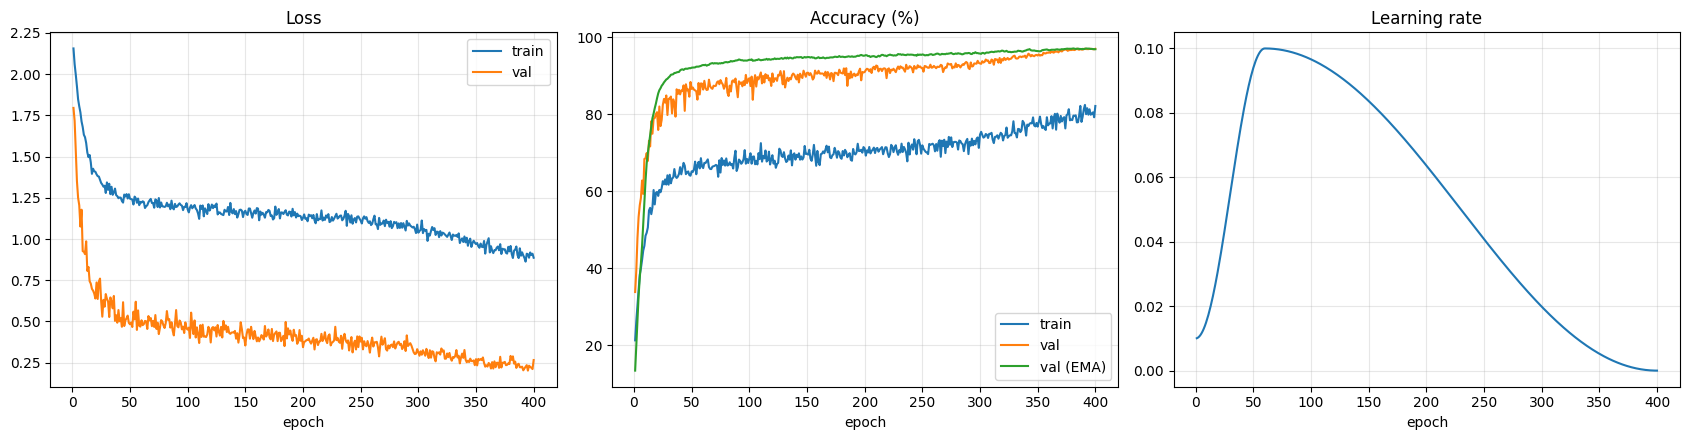

In [13]:
ep = range(1, len(hist["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, hist["train_acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="val")
ax[1].plot(ep, hist["ema_val_acc"], label="val (EMA)"); ax[1].set_title("Accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[2].plot(ep, hist["lr"]); ax[2].set_title("Learning rate"); ax[2].set_xlabel("epoch")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "curves.png"), dpi=150); plt.show()

## 7. Final evaluation

In [14]:
final_model = ResNet().to(device)
final_model.load_state_dict(torch.load(os.path.join(OUT_DIR, "best.pt"), map_location=device))
_, acc_plain = evaluate(final_model, val_loader)
_, acc_tta = evaluate(final_model, val_loader, tta=True)
n_params = sum(p.numel() for p in final_model.parameters() if p.requires_grad)
print(f"Number of trainable parameters: {n_params:,}")
print(f"Final validation accuracy (held-out 5k)        : {acc_plain:.2f}%")
print(f"Final validation accuracy (with flip TTA)      : {acc_tta:.2f}%")

Number of trainable parameters: 4,623,178
Final validation accuracy (held-out 5k)        : 97.08%
Final validation accuracy (with flip TTA)      : 97.16%


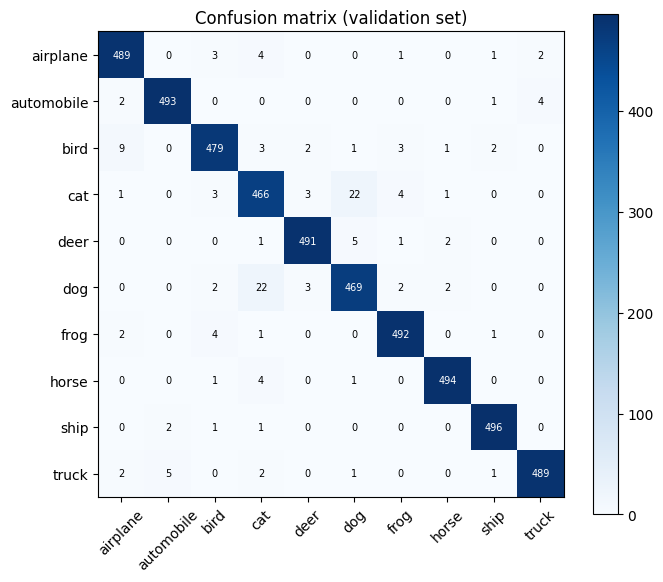

  airplane: 97.80%
automobile: 98.60%
      bird: 95.80%
       cat: 93.20%
      deer: 98.20%
       dog: 93.80%
      frog: 98.40%
     horse: 98.80%
      ship: 99.20%
     truck: 97.80%


In [15]:
# Confusion matrix + per-class accuracy
from sklearn.metrics import confusion_matrix
final_model.eval(); preds = []
with torch.no_grad():
    for x, _ in val_loader:
        x = x.to(device)
        with torch.autocast(device.type, enabled=USE_AMP):
            preds.append(tta_logits(final_model, x).argmax(1).cpu())
preds = torch.cat(preds).numpy()
cm = confusion_matrix(y_val, preds)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(10), CLASSES, rotation=45); plt.yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.title("Confusion matrix (validation set)"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion.png"), dpi=150); plt.show()
for c, a in zip(CLASSES, cm.diagonal() / cm.sum(1)): print(f"{c:>10s}: {100*a:.2f}%")

## 8. Kaggle submission

In [16]:
final_model.eval(); test_preds = []
with torch.no_grad():
    for x in test_loader:
        x = x.to(device)
        with torch.autocast(device.type, enabled=USE_AMP):
            logits = tta_logits(final_model, x)
        test_preds.append(logits.argmax(1).cpu())
test_preds = torch.cat(test_preds).numpy()

sub = pd.DataFrame({"id": test_ids, "label": test_preds})
sub_path = os.path.join(OUT_DIR, "submission.csv")
sub.to_csv(sub_path, index=False)
print(sub.head()); print("saved", sub_path, "| rows:", len(sub))
print("prediction class distribution:", np.bincount(test_preds, minlength=10))

   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3
saved ./outputs/submission.csv | rows: 2000
prediction class distribution: [175 223 208 203 202 205 187 204 203 190]


## 9. Reference

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)* (pp. 770-778). https://doi.org/10.1109/CVPR.2016.90